<a href="https://colab.research.google.com/github/jatinkumar-creator/machine-learning-portfolio/blob/main/05_Classification/notebooks/02_Multiclass_Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    log_loss
)

In [2]:
#Load the Iris dataset
iris = load_iris()

X = iris.data
y = iris.target

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("Classes:", iris.target_names)

Feature shape: (150, 4)
Target shape: (150,)
Classes: ['setosa' 'versicolor' 'virginica']


In [3]:
#Create a DataFrame
df = pd.DataFrame(
    X,
    columns=iris.feature_names
)

df["Target"] = y

df["Flower_Name"] = df["Target"].map(
    dict(enumerate(iris.target_names))
)

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Target,Flower_Name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [4]:
#Explore class distribution
print(df["Flower_Name"].value_counts())

Flower_Name
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [5]:
#Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


In [6]:
#Build the Multinomial Logistic Regression model
multinomial_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        solver="lbfgs",
        max_iter=1000
    ))
])

In [7]:
#Train the model
multinomial_model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('logistic', LogisticRegression(max_iter=1000))])

In [8]:
#Make predictions
y_pred = multinomial_model.predict(X_test)

print("Actual classes:")
print(y_test[:10])

print("\nPredicted classes:")
print(y_pred[:10])

Actual classes:
[0 2 1 1 0 1 0 0 2 1]

Predicted classes:
[0 2 1 1 0 1 0 0 2 1]


In [9]:
#Generate probability predictions
y_prob = multinomial_model.predict_proba(X_test)

print(y_prob[:10])

probability_df = pd.DataFrame(
    y_prob,
    columns=iris.target_names
)

probability_df["Predicted_Class"] = iris.target_names[
    y_pred
]

probability_df.head(10)

print(y_prob.sum(axis=1)[:10])

[[9.78818005e-01 2.11816311e-02 3.63821812e-07]
 [3.79836951e-03 3.69220168e-01 6.26981463e-01]
 [1.48799040e-01 8.42474895e-01 8.72606441e-03]
 [9.54449962e-02 8.94618634e-01 9.93636953e-03]
 [9.88493051e-01 1.15067767e-02 1.72549650e-07]
 [1.80467404e-02 6.75523476e-01 3.06429784e-01]
 [9.96229748e-01 3.77022246e-03 2.97022191e-08]
 [9.41042080e-01 5.89566205e-02 1.29921391e-06]
 [4.11857155e-04 1.43890739e-01 8.55697404e-01]
 [5.99589760e-02 7.37092831e-01 2.02948193e-01]]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [10]:
#Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.9333333333333333


[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


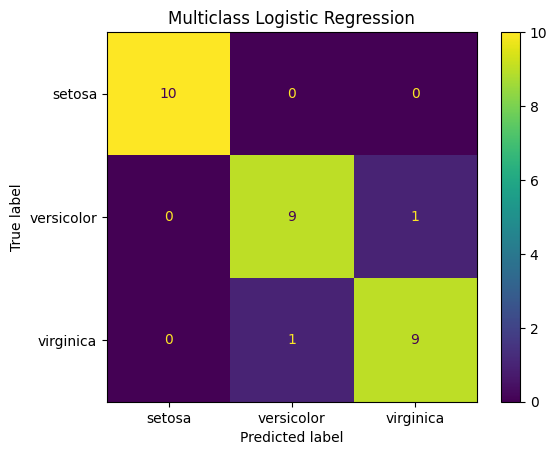

In [11]:
#Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print(cm)

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=iris.target_names
)

plt.title("Multiclass Logistic Regression")
plt.show()

In [12]:
#Classification Report
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    )
)

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [13]:
#Calculate Multiclass Log Loss
loss = log_loss(y_test, y_prob)

print("Multiclass Log Loss:", loss)

Multiclass Log Loss: 0.1739725930652045


In [14]:
#Create OvR model
ovr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("ovr", OneVsRestClassifier(
        LogisticRegression(max_iter=1000)
    ))
])

In [15]:
#Train OvR
ovr_model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('ovr',
                 OneVsRestClassifier(estimator=LogisticRegression(max_iter=1000)))])

In [16]:
#Make OvR predictions
ovr_predictions = ovr_model.predict(X_test)

ovr_probabilities = ovr_model.predict_proba(X_test)

print("OvR Accuracy:",
      accuracy_score(y_test, ovr_predictions))

print("OvR Log Loss:",
      log_loss(y_test, ovr_probabilities))

OvR Accuracy: 0.9
OvR Log Loss: 0.32521886418168017


In [17]:
#Compare both models
comparison = pd.DataFrame({
    "Model": [
        "Multinomial Logistic Regression",
        "One-vs-Rest Logistic Regression"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, ovr_predictions)
    ],
    "Log Loss": [
        log_loss(y_test, y_prob),
        log_loss(y_test, ovr_probabilities)
    ]
})

comparison

,Model,Accuracy,Log Loss
0,Multinomial Logistic Regression,0.933333,0.173973
1,One-vs-Rest Logistic Regression,0.900000,0.325219
